In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, pickle, time, warnings
import numpy as np, pandas as pd
import cv2, matplotlib.pyplot as plt, seaborn as sns
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
warnings.filterwarnings("ignore")

RANDOM_STATE = 42   # fixé pour la reproductibilité du split et des modèles
# Dossier du Drive contenant les fichiers data_batch_1..5 et test_batch de CIFAR-10 (version python)
DATA_DIR = "/content/drive/MyDrive/image_mining/atelier2/DB2C"

In [3]:
import os

if os.path.exists(DATA_DIR):
    print(f" Le dossier existe bien : {DATA_DIR}")
    files = os.listdir(DATA_DIR)
    print(f"Fichiers trouvés ({len(files)}) :", files)
else:
    print(f" Le dossier n'existe pas : {DATA_DIR}")
    # Recherche de dossiers alternatifs ou suggestion d'exploration
    parent_dir = os.path.dirname(DATA_DIR)
    if os.path.exists(parent_dir):
        print(f"Le dossier parent existe et contient : {os.listdir(parent_dir)}")

 Le dossier existe bien : /content/drive/MyDrive/image_mining/atelier2/DB2C
Fichiers trouvés (3) : ['obj_ship', 'obj_car', 'comparaison_modeles.csv']


## Étape A — Préparer et explorer les images

X_train: (392, 32, 32, 3) | y_train: (392,)
X_test : (99, 32, 32, 3) | y_test : (99,)
Répartition train: [ 72 320] | test: [18 81]


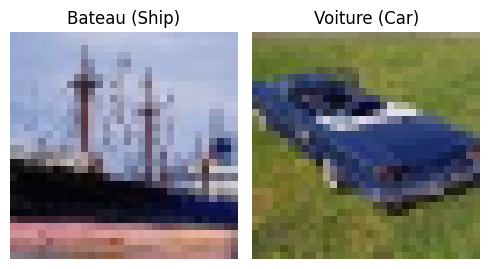

In [4]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def preprocess_image(img_rgb, size=32):
    """Prétraitement UNIQUE, à recopier à l'identique dans app.py.
    1) recadrage carré centré (pas de déformation de l'image)
    2) réduction avec INTER_AREA (anti-aliasing) -> indispensable pour une grande photo
    3) float32 dans [0, 1]
    """
    h, w = img_rgb.shape[:2]
    s = min(h, w)
    y0, x0 = (h - s) // 2, (w - s) // 2
    img = img_rgb[y0:y0 + s, x0:x0 + s]
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return img.astype(np.float32) / 255.0

def load_images_from_folder(folder, label, img_size=(32, 32)):
    images = []
    labels = []
    if not os.path.exists(folder):
        print(f" Dossier introuvable : {folder}")
        return images, labels

    for filename in os.listdir(folder):
        img_path = os.path.join(folder, filename)
        # Lecture de l'image
        img = cv2.imread(img_path)
        if img is not None:
            # Conversion de BGR (OpenCV) à RGB
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            # Redimensionnement uniforme
            img = preprocess_image(img, img_size[0])
            images.append(img)
            labels.append(label)
    return images, labels

# Dossiers pour chaque classe
ship_dir = os.path.join(DATA_DIR, "obj_ship")
car_dir = os.path.join(DATA_DIR, "obj_car")

# Chargement des images
ships_X, ships_y = load_images_from_folder(ship_dir, label=0)
cars_X, cars_y = load_images_from_folder(car_dir, label=1)

# Combinaison et normalisation dans [0, 1]
X = np.array(ships_X + cars_X, dtype="float32")   # déjà dans [0, 1]
y = np.array(ships_y + cars_y)

class_names = ["Bateau (Ship)", "Voiture (Car)"]

# Split stratifié
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Affichage des dimensions et des statistiques
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test :", X_test.shape,  "| y_test :", y_test.shape)
print("Répartition train:", np.bincount(y_train), "| test:", np.bincount(y_test))

# Aperçu des images
fig, ax = plt.subplots(1, 2, figsize=(5, 3))
for c in range(2):
    idx = np.where(y_train == c)[0]
    if len(idx) > 0:
        ax[c].imshow(X_train[idx[0]])
        ax[c].set_title(class_names[c])
    ax[c].axis("off")
plt.tight_layout()
plt.show()

In [5]:
# DIAGNOSTIC : quelle est la taille ORIGINALE des images d'entraînement ?
# Si tout est en 32x32, une grande photo importée dans l'appli est très différente (changement de domaine).
import collections
sizes = collections.Counter()
for d in (ship_dir, car_dir):
    for f in os.listdir(d)[:300]:
        im = cv2.imread(os.path.join(d, f))
        if im is not None:
            sizes[im.shape[:2]] += 1
print(sizes.most_common(10))
print("Déséquilibre : bateaux =", int((y == 0).sum()), "| voitures =", int((y == 1).sum()))


[((80, 120), 385), ((120, 80), 5)]
Déséquilibre : bateaux = 90 | voitures = 401


**Intérêt de la séparation apprentissage/test :** *(à rédiger avec vos mots : évaluer la généralisation sur des images jamais vues, détecter le surapprentissage.)*

## Étape B — Extraction des caractéristiques
RGB (moyenne/écart-type), histogramme HSV, GLCM, LBP, moments de Hu.

In [6]:
import time, warnings
import pandas as pd, seaborn as sns
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
warnings.filterwarnings("ignore")

def extract_features(img):
    img8 = (img * 255).astype(np.uint8)
    # 1) Statistiques RGB : moyenne et écart-type par canal (6)
    rgb = np.concatenate([img.mean(axis=(0, 1)), img.std(axis=(0, 1))])
    # 2) Histogramme HSV : 8 bins par canal (24)
    hsv = cv2.cvtColor(img8, cv2.COLOR_RGB2HSV)
    hist = np.concatenate([
        cv2.calcHist([hsv], [0], None, [8], [0, 180]).ravel(),
        cv2.calcHist([hsv], [1], None, [8], [0, 256]).ravel(),
        cv2.calcHist([hsv], [2], None, [8], [0, 256]).ravel()])
    hist = hist / (hist.sum() + 1e-8)
    gray = cv2.cvtColor(img8, cv2.COLOR_RGB2GRAY)
    # 3) GLCM : 5 propriétés x 4 angles (20)
    glcm = graycomatrix(gray // 8, distances=[1],
                        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                        levels=32, symmetric=True, normed=True)
    glcm_f = np.concatenate([graycoprops(glcm, p).ravel() for p in
             ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]])
    # 4) LBP uniforme (P=8, R=1) : histogramme de 10 bins (10)
    lbp = local_binary_pattern(gray, 8, 1, method="uniform")
    lbp_h, _ = np.histogram(lbp, bins=np.arange(0, 11), density=True)
    # 5) Moments de Hu (7), échelle logarithmique
    hu = cv2.HuMoments(cv2.moments(gray)).ravel()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-12)
    return np.concatenate([rgb, hist, glcm_f, lbp_h, hu])

t0 = time.time()
F_train = np.array([extract_features(i) for i in X_train])
F_test  = np.array([extract_features(i) for i in X_test])
print("F_train:", F_train.shape, "| F_test:", F_test.shape, f"| {time.time()-t0:.1f}s")
# une ligne = une image ; une colonne = une caractéristique (67 au total)

F_train: (392, 67) | F_test: (99, 67) | 1.0s


**Lecture de la matrice :** une ligne = une image, une colonne = une caractéristique (67 au total).

**Pourquoi des vecteurs de caractéristiques plutôt que les pixels bruts :** *(à rédiger avec vos mots.)*

## Étape C/E — Apprentissage avec GridSearchCV
**6 modèles** (4 noyaux SVM, KNN, arbre de décision), chacun optimisé par grid search (validation croisée 5 plis sur l'ensemble d'apprentissage uniquement). Classes déséquilibrées : `class_weight="balanced"` et métrique `balanced_accuracy`. La standardisation est dans le pipeline pour éviter toute fuite de données.


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Même validation croisée pour tous les modèles (reproductible)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Classes déséquilibrées (~80 % voitures) -> on optimise la balanced accuracy, pas l'accuracy simple
SCORING = "balanced_accuracy"

def svc(**kw):
    # class_weight="balanced" : compense le manque de bateaux ; probability=True : scores affichables dans l'appli
    return SVC(class_weight="balanced", probability=True, random_state=RANDOM_STATE, **kw)

# Chaque modèle : (estimateur, grille). Le pipeline s'appelle toujours scaler -> clf.
models = {
    "SVM RBF":        (svc(),                 {"clf__kernel": ["rbf"],     "clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.001]}),
    "SVM Linéaire":   (svc(),                 {"clf__kernel": ["linear"],  "clf__C": [0.01, 0.1, 1, 10]}),
    "SVM Sigmoïde":   (svc(),                 {"clf__kernel": ["sigmoid"], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.01, 0.001]}),
    "SVM Polynomial": (svc(),                 {"clf__kernel": ["poly"],    "clf__C": [0.1, 1, 10], "clf__degree": [2, 3]}),
    # KNN : on optimise aussi k (avant, k était fixé à la main et non validé)
    "KNN":            (KNeighborsClassifier(), {"clf__n_neighbors": [3, 5, 7, 9, 11, 15], "clf__weights": ["uniform", "distance"]}),
    "Arbre de décision": (DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
                          {"clf__max_depth": [3, 5, 8, None], "clf__min_samples_leaf": [1, 3, 5]}),
}

fitted, rows = {}, []

def evaluate(name, model, params, cv_mean, cv_std, fit_time):
    y_pred = model.predict(F_test)
    rows.append({
        "Modèle": name, "Paramètres": params,
        "Bal. Acc. CV (moy)": cv_mean, "Bal. Acc. CV (écart-type)": cv_std,
        "Accuracy (test)": accuracy_score(y_test, y_pred),
        "Bal. Acc. (test)": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),                  # positive = Voiture
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "Recall Bateau": recall_score(y_test, y_pred, pos_label=0),   # la classe rare : à surveiller
        "Temps (s)": fit_time})
    fitted[name] = model

for name, (estimator, grid) in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", estimator)])
    gs = GridSearchCV(pipe, grid, cv=skf, scoring=SCORING, n_jobs=-1)
    t0 = time.time(); gs.fit(F_train, y_train); dt = time.time() - t0
    best = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    std = gs.cv_results_["std_test_score"][gs.best_index_]
    evaluate(name, gs.best_estimator_, best, gs.best_score_, std, dt)
    print(f"{name}: {best} | CV bal.acc={gs.best_score_:.4f} ± {std:.4f} | {dt:.1f}s")


SVM RBF: {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'} | CV bal.acc=0.9763 ± 0.0233 | 5.6s
SVM Linéaire: {'C': 0.1, 'kernel': 'linear'} | CV bal.acc=0.9728 ± 0.0177 | 0.5s
SVM Sigmoïde: {'C': 10, 'gamma': 0.001, 'kernel': 'sigmoid'} | CV bal.acc=0.9650 ± 0.0222 | 1.8s
SVM Polynomial: {'C': 1, 'degree': 2, 'kernel': 'poly'} | CV bal.acc=0.9340 ± 0.0493 | 0.8s
KNN: {'n_neighbors': 3, 'weights': 'uniform'} | CV bal.acc=0.9427 ± 0.0516 | 0.4s
Arbre de décision: {'max_depth': 3, 'min_samples_leaf': 3} | CV bal.acc=0.8988 ± 0.0190 | 0.7s


## Étape C2 — Prédiction sur une image de test

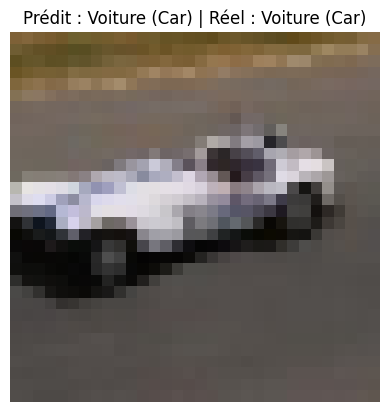

Meilleur modèle : SVM RBF | classe positive = Voiture


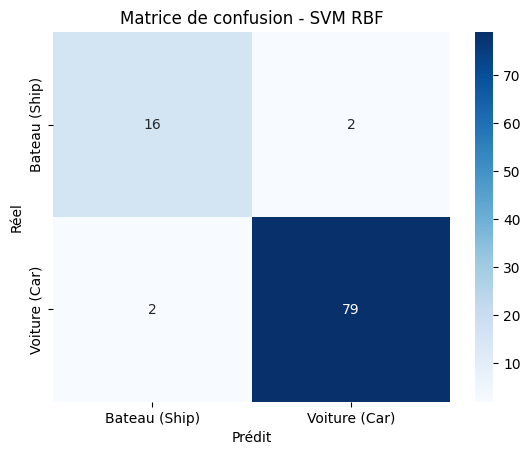

               precision    recall  f1-score   support

Bateau (Ship)     0.8889    0.8889    0.8889        18
Voiture (Car)     0.9753    0.9753    0.9753        81

     accuracy                         0.9596        99
    macro avg     0.9321    0.9321    0.9321        99
 weighted avg     0.9596    0.9596    0.9596        99



In [8]:
# Prédiction sur une image de test (SVM RBF)
idx = 0
pred = fitted["SVM RBF"].predict(F_test[idx:idx+1])[0]
plt.imshow(X_test[idx]); plt.axis("off")
plt.title(f"Prédit : {class_names[pred]} | Réel : {class_names[y_test[idx]]}")
plt.show()

# Évaluation détaillée du meilleur modèle
res = pd.DataFrame(rows)
best_name = res.loc[res["Bal. Acc. CV (moy)"].idxmax(), "Modèle"]
y_pred = fitted[best_name].predict(F_test)
print("Meilleur modèle :", best_name, "| classe positive = Voiture")

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.title(f"Matrice de confusion - {best_name}"); plt.show()

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

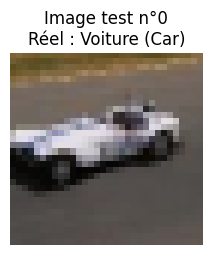

,Modèle,Prédiction,Étiquette réelle,Correct
0,SVM RBF,Voiture (Car),Voiture (Car),✅
1,SVM Linéaire,Voiture (Car),Voiture (Car),✅
2,SVM Sigmoïde,Voiture (Car),Voiture (Car),✅
3,SVM Polynomial,Voiture (Car),Voiture (Car),✅
4,KNN,Voiture (Car),Voiture (Car),✅
5,Arbre de décision,Voiture (Car),Voiture (Car),✅


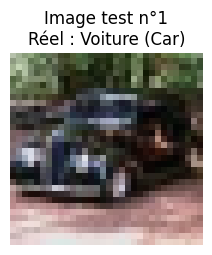

,Modèle,Prédiction,Étiquette réelle,Correct
0,SVM RBF,Voiture (Car),Voiture (Car),✅
1,SVM Linéaire,Voiture (Car),Voiture (Car),✅
2,SVM Sigmoïde,Voiture (Car),Voiture (Car),✅
3,SVM Polynomial,Voiture (Car),Voiture (Car),✅
4,KNN,Voiture (Car),Voiture (Car),✅
5,Arbre de décision,Voiture (Car),Voiture (Car),✅


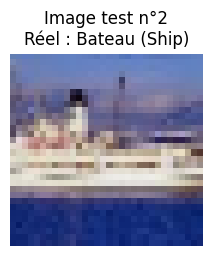

,Modèle,Prédiction,Étiquette réelle,Correct
0,SVM RBF,Bateau (Ship),Bateau (Ship),✅
1,SVM Linéaire,Bateau (Ship),Bateau (Ship),✅
2,SVM Sigmoïde,Bateau (Ship),Bateau (Ship),✅
3,SVM Polynomial,Voiture (Car),Bateau (Ship),❌
4,KNN,Bateau (Ship),Bateau (Ship),✅
5,Arbre de décision,Bateau (Ship),Bateau (Ship),✅


Meilleur modèle : SVM RBF | classe positive = Voiture


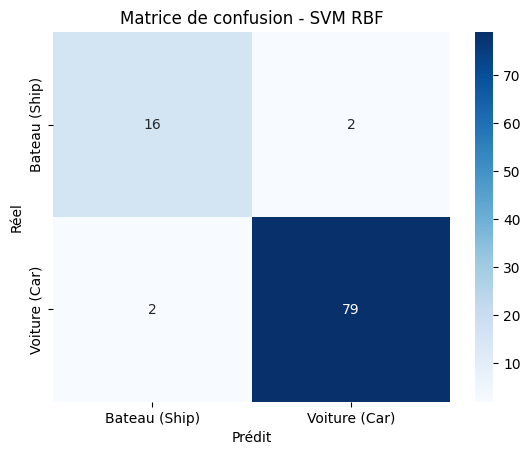

               precision    recall  f1-score   support

Bateau (Ship)     0.8889    0.8889    0.8889        18
Voiture (Car)     0.9753    0.9753    0.9753        81

     accuracy                         0.9596        99
    macro avg     0.9321    0.9321    0.9321        99
 weighted avg     0.9596    0.9596    0.9596        99



In [9]:
# --- Prédiction de TOUS les modèles sur quelques images de test ---
indices = [0, 1, 2]   # change ces indices pour tester d'autres images

for idx in indices:
    vraie = class_names[y_test[idx]]

    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(X_test[idx]); plt.axis("off")
    plt.title(f"Image test n°{idx}\nRéel : {vraie}")
    plt.show()

    lignes = []
    for name, model in fitted.items():
        p = model.predict(F_test[idx:idx+1])[0]
        lignes.append({"Modèle": name,
                       "Prédiction": class_names[p],
                       "Étiquette réelle": vraie,
                       "Correct": "✅" if p == y_test[idx] else "❌"})
    display(pd.DataFrame(lignes))

# --- Évaluation détaillée du meilleur modèle ---
res = pd.DataFrame(rows)
best_name = res.loc[res["Bal. Acc. CV (moy)"].idxmax(), "Modèle"]
y_pred = fitted[best_name].predict(F_test)
print("Meilleur modèle :", best_name, "| classe positive = Voiture")

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.title(f"Matrice de confusion - {best_name}"); plt.show()

print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

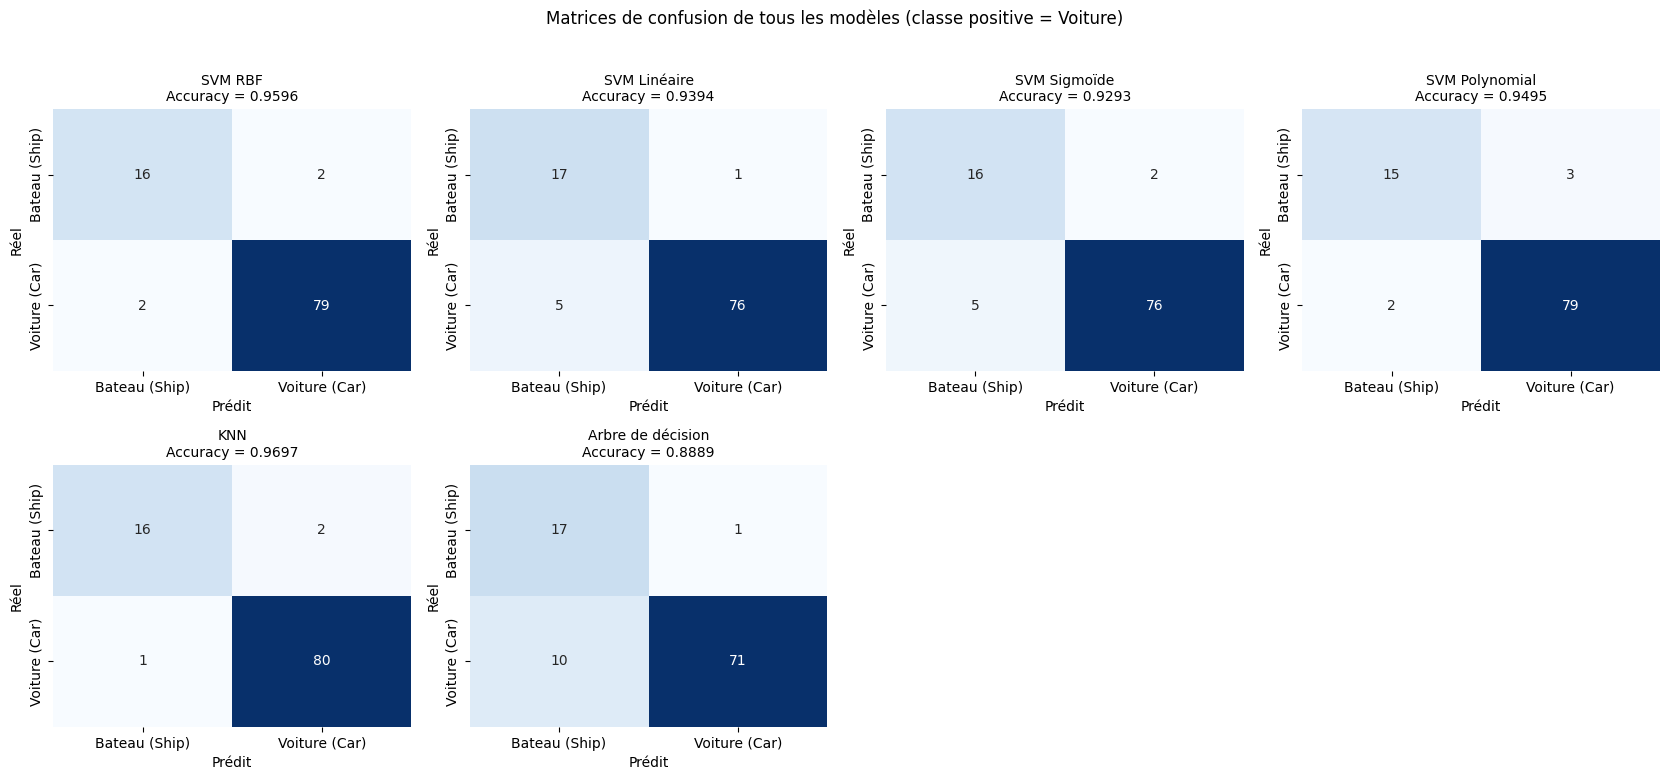

SVM RBF
               precision    recall  f1-score   support

Bateau (Ship)     0.8889    0.8889    0.8889        18
Voiture (Car)     0.9753    0.9753    0.9753        81

     accuracy                         0.9596        99
    macro avg     0.9321    0.9321    0.9321        99
 weighted avg     0.9596    0.9596    0.9596        99

SVM Linéaire
               precision    recall  f1-score   support

Bateau (Ship)     0.7727    0.9444    0.8500        18
Voiture (Car)     0.9870    0.9383    0.9620        81

     accuracy                         0.9394        99
    macro avg     0.8799    0.9414    0.9060        99
 weighted avg     0.9481    0.9394    0.9417        99

SVM Sigmoïde
               precision    recall  f1-score   support

Bateau (Ship)     0.7619    0.8889    0.8205        18
Voiture (Car)     0.9744    0.9383    0.9560        81

     accuracy                         0.9293        99
    macro avg     0.8681    0.9136    0.8882        99
 weighted avg     0.935

In [10]:
import math

noms = list(fitted.keys())
n_cols = 4
n_rows = math.ceil(len(noms) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.8 * n_rows))
axes = np.array(axes).ravel()

for ax, name in zip(axes, noms):
    y_pred_m = fitted[name].predict(F_test)
    cm = confusion_matrix(y_test, y_pred_m)
    acc = accuracy_score(y_test, y_pred_m)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {acc:.4f}", fontsize=10)
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")

# Masquer les cases vides de la grille
for ax in axes[len(noms):]:
    ax.axis("off")

plt.suptitle("Matrices de confusion de tous les modèles (classe positive = Voiture)", y=1.02)
plt.tight_layout()
plt.show()

# Rapport de classification de chaque modèle
for name in noms:
    print("=" * 60)
    print(name)
    print(classification_report(y_test, fitted[name].predict(F_test),
                                target_names=class_names, digits=4))

Interprétation : (VP, VN, FP, FN ; une bonne accuracy ne garantit pas que les deux classes sont bien reconnues : comparer precision/recall par classe.)

## Tableau comparatif final

,Modèle,Paramètres,Bal. Acc. CV (moy),Bal. Acc. CV (écart-type),Accuracy (test),Bal. Acc. (test),Precision,Recall,F1-score,Recall Bateau,Temps (s)
1,SVM RBF,"{'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}",0.9763,0.023309,0.9596,0.9321,0.9753,0.9753,0.9753,0.8889,5.6
2,SVM Linéaire,"{'C': 0.1, 'kernel': 'linear'}",0.9728,0.017701,0.9394,0.9414,0.9870,0.9383,0.9620,0.9444,0.5
3,SVM Sigmoïde,"{'C': 10, 'gamma': 0.001, 'kernel': 'sigmoid'}",0.9650,0.022174,0.9293,0.9136,0.9744,0.9383,0.9560,0.8889,1.8
4,KNN,"{'n_neighbors': 3, 'weights': 'uniform'}",0.9427,0.051627,0.9697,0.9383,0.9756,0.9877,0.9816,0.8889,0.4
5,SVM Polynomial,"{'C': 1, 'degree': 2, 'kernel': 'poly'}",0.9340,0.049341,0.9495,0.9043,0.9634,0.9753,0.9693,0.8333,0.8
6,Arbre de décision,"{'max_depth': 3, 'min_samples_leaf': 3}",0.8988,0.019021,0.8889,0.9105,0.9861,0.8765,0.9281,0.9444,0.7


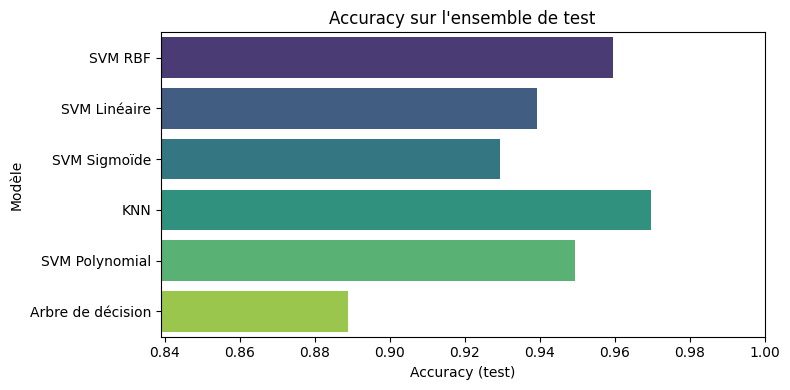

In [11]:
res = pd.DataFrame(rows).sort_values("Bal. Acc. CV (moy)", ascending=False).reset_index(drop=True)
res.index += 1
display(res.style.format({"Bal. Acc. CV (moy)": "{:.4f}", "Bal. Acc. (test)": "{:.4f}", "Recall Bateau": "{:.4f}", "Accuracy (test)": "{:.4f}", "Precision": "{:.4f}",
                          "Recall": "{:.4f}", "F1-score": "{:.4f}", "Temps (s)": "{:.1f}"}, na_rep="-")
        .background_gradient(subset=["Accuracy (test)"], cmap="Greens"))

res.to_csv("/content/drive/MyDrive/comparaison_modeles.csv", index=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=res, y="Modèle", x="Accuracy (test)", palette="viridis")
plt.xlim(res["Accuracy (test)"].min() - 0.05, 1); plt.title("Accuracy sur l'ensemble de test"); plt.tight_layout(); plt.show()

In [12]:
print("rows existe :", "rows" in globals())
print("fitted existe :", "fitted" in globals())
print("class_names existe :", "class_names" in globals())

rows existe : True
fitted existe : True
class_names existe : True


In [13]:
import pandas as pd
import joblib
from sklearn.base import clone

res = pd.DataFrame(rows)

# Choix sur la validation croisée (jamais sur le test) -> pas de sélection sur 1 image d'écart
best_name = res.loc[res["Bal. Acc. CV (moy)"].idxmax(), "Modèle"]
print("Modèle sélectionné :", best_name)
print(res.loc[res["Modèle"] == best_name, ["Accuracy (test)", "Bal. Acc. (test)", "Recall Bateau"]].round(4).to_string(index=False))

# Une fois le choix fait, on réentraîne sur train + test (plus de bateaux = meilleur modèle)
F_all = np.vstack([F_train, F_test])
y_all = np.concatenate([y_train, y_test])
final_model = clone(fitted[best_name]).fit(F_all, y_all)

joblib.dump(
    {
        "model": final_model,
        "model_name": best_name,
        "class_names": class_names,
    },
    "/content/modele_classification.pkl"
)
print("Modèle sauvegardé avec succès !")


Modèle sélectionné : SVM RBF
 Accuracy (test)  Bal. Acc. (test)  Recall Bateau
          0.9596            0.9321         0.8889
Modèle sauvegardé avec succès !


# **Conclusion**

*(À réécrire avec vos propres résultats après avoir relancé le notebook : modèle retenu sur la validation croisée, balanced accuracy, recall de la classe Bateau, et limites — peu de bateaux (≈ 90 images), changement de domaine entre les images d'entraînement et les photos importées dans l'appli.)*


In [14]:
import joblib
import os

chemin = "/content/modele_classification.pkl"

print("Le fichier existe :", os.path.exists(chemin))

if os.path.exists(chemin):
    print("Taille du fichier :", os.path.getsize(chemin), "octets")

    try:
        modele = joblib.load(chemin)

        print("Modèle chargé avec succès !")
        print("Type du contenu :", type(modele))

        if isinstance(modele, dict):
            print("Clés disponibles :", modele.keys())

    except Exception as e:
        print("Erreur pendant le chargement :", repr(e))

Le fichier existe : True
Taille du fichier : 83255 octets
Modèle chargé avec succès !
Type du contenu : <class 'dict'>
Clés disponibles : dict_keys(['model', 'model_name', 'class_names'])


In [15]:
import os
import binascii

chemin = "/content/modele_classification.pkl"

with open(chemin, "rb") as f:
    debut = f.read(32)

print("Taille :", os.path.getsize(chemin), "octets")
print("Premiers octets :", binascii.hexlify(debut).decode())
print("En-tête lisible :", repr(debut))

Taille : 83255 octets
Premiers octets : 800495f2010000000000007d94288c056d6f64656c948c10736b6c6561726e2e
En-tête lisible : b'\x80\x04\x95\xf2\x01\x00\x00\x00\x00\x00\x00}\x94(\x8c\x05model\x94\x8c\x10sklearn.'


In [16]:

import joblib

chemin = "/content/modele_classification.pkl"

try:
    modele = joblib.load(chemin)
    print("Chargement réussi !")
    print("Type :", type(modele))

    if isinstance(modele, dict):
        print("Clés :", list(modele.keys()))

        for cle, valeur in modele.items():
            print(f"{cle} : {type(valeur)}")
except Exception as e:
    print("Erreur :", repr(e))


Chargement réussi !
Type : <class 'dict'>
Clés : ['model', 'model_name', 'class_names']
model : <class 'sklearn.pipeline.Pipeline'>
model_name : <class 'str'>
class_names : <class 'list'>


In [17]:
print("Nom du modèle :", modele["model_name"])
print("Classes :", modele["class_names"])
print("Étapes du pipeline :", modele["model"].named_steps)

Nom du modèle : SVM RBF
Classes : ['Bateau (Ship)', 'Voiture (Car)']
Étapes du pipeline : {'scaler': StandardScaler(), 'clf': SVC(C=1, class_weight='balanced', gamma=0.01, probability=True, random_state=42)}


In [18]:
from google.colab import files

files.download("/content/modele_classification.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import sklearn
import numpy
import cv2
import skimage
import joblib

print("scikit-learn :", sklearn.__version__)
print("numpy :", numpy.__version__)
print("opencv :", cv2.__version__)
print("scikit-image :", skimage.__version__)
print("joblib :", joblib.__version__)

scikit-learn : 1.6.1
numpy : 2.1.3
opencv : 4.14.0
scikit-image : 0.25.2
joblib : 1.6.0
